## Smart Expense Classifier - Arabic

**Dataset:** Arabic Transaction Dataset with Diacritics


## 1. Setup & Imports

In [1]:
# Standard libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
from collections import Counter
import joblib
import time
import json
from datetime import datetime

# Scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Arabic text processing
import arabic_reshaper
from bidi.algorithm import get_display

# Settings
warnings.filterwarnings('ignore')
plt.style.use('default')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Configure matplotlib for Arabic text display
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)



## 2. Load Balanced Arabic Dataset

In [2]:
# Load the balanced Arabic dataset with diacritics
print("📂 Loading Balanced Arabic Dataset with Diacritics...")
start_time = time.time()

# Try different possible locations
data_paths = [
    '../data/raw/arabic_balanced_diacritics_clean.csv',
    'data/raw/arabic_balanced_diacritics_clean.csv',
    '../data/arabic_balanced_diacritics_clean.csv'
]

df = None
for path in data_paths:
    try:
        df = pd.read_csv(path, encoding='utf-8')
        print(f" Dataset loaded from: {path}")
        break
    except:
        continue

if df is None:
    print(" Dataset not found! Please run generate_balanced_arabic_diacritics.py first.")
else:
    load_time = time.time() - start_time
    print(f"  Loading time: {load_time:.2f} seconds")
    print(f" Dataset shape: {df.shape}")
    print(f" Columns: {list(df.columns)}")

📂 Loading Balanced Arabic Dataset with Diacritics...
 Dataset loaded from: ../data/raw/arabic_balanced_diacritics_clean.csv
  Loading time: 0.11 seconds
 Dataset shape: (10000, 4)
 Columns: ['transaction_description', 'category', 'country', 'currency']


In [3]:

print("\n First 5 records:")
df.head()


 First 5 records:


,transaction_description,category,country,currency
0,دفعت للبنك الصراف الآلي,Financial Services,Egypt,EGP
1,كشف عند المستشفى,Healthcare & Medical,Egypt,EGP
2,رحلة تَاكْسِي أَبْيَضْ,Transportation,Egypt,EGP
3,روحت مُسْتَوْصَفٌ,Healthcare & Medical,Egypt,EGP
4,شراء دواء من الْمُخْتَبَرُ,Healthcare & Medical,Egypt,EGP


In [4]:

print("\n Dataset Information:")
df.info()


 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   transaction_description  10000 non-null  object
 1   category                 10000 non-null  object
 2   country                  10000 non-null  object
 3   currency                 10000 non-null  object
dtypes: object(4)
memory usage: 312.6+ KB


## 3. Exploratory Data Analysis (EDA)

In [5]:

print(" Missing Values:")
print(df.isnull().sum())
print(f"\nTotal missing: {df.isnull().sum().sum()}")

 Missing Values:
transaction_description    0
category                   0
country                    0
currency                   0
dtype: int64

Total missing: 0



 Category Distribution (Should be EQUAL):
category
Charity & Donations           1000
Entertainment & Recreation    1000
Financial Services            1000
Food & Dining                 1000
Government & Legal            1000
Healthcare & Medical          1000
Income                        1000
Shopping & Retail             1000
Transportation                1000
Utilities & Services          1000
Name: count, dtype: int64


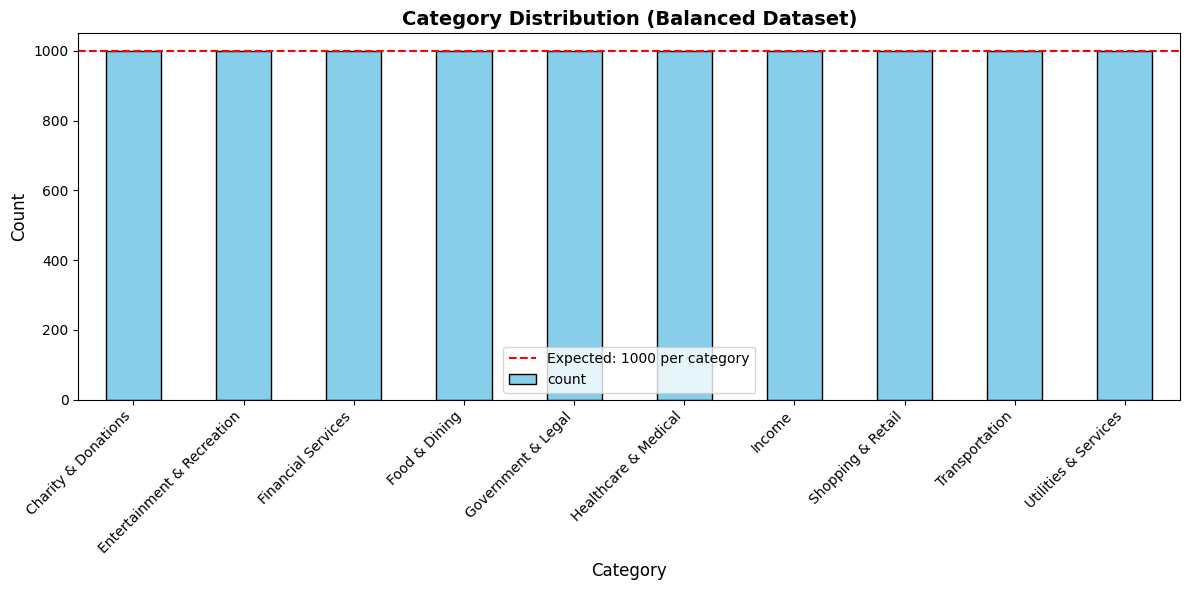


 Dataset is PERFECTLY BALANCED!


In [6]:
# Category distribution (should be perfectly balanced)
print("\n Category Distribution (Should be EQUAL):")
print(df['category'].value_counts().sort_index())

# Visualize
plt.figure(figsize=(12, 6))
df['category'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Category Distribution (Balanced Dataset)', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.axhline(y=1000, color='red', linestyle='--', label='Expected: 1000 per category')
plt.legend()
plt.tight_layout()
plt.show()

# Check if balanced
category_counts = df['category'].value_counts()
if category_counts.std() == 0:
    print("\n Dataset is PERFECTLY BALANCED!")
else:
    print(f"\n  Dataset has slight imbalance. Std: {category_counts.std():.2f}")


 Text Length Statistics:
count    10000.000000
mean        23.607000
std          8.161275
min          7.000000
25%         17.000000
50%         22.000000
75%         29.000000
max         63.000000
Name: text_length, dtype: float64


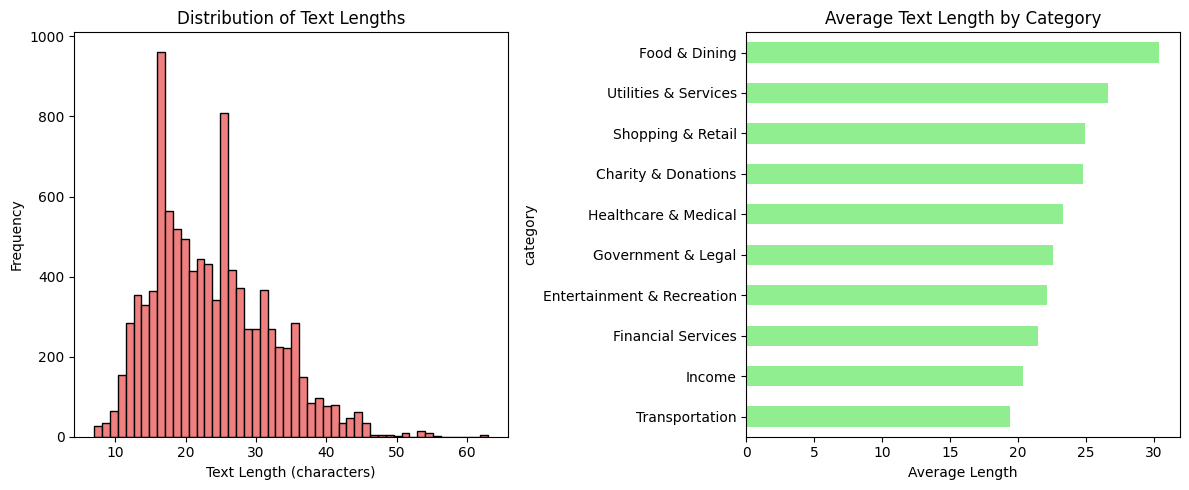

In [7]:
# Text length analysis
df['text_length'] = df['transaction_description'].str.len()

print("\n Text Length Statistics:")
print(df['text_length'].describe())

# Visualize
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['text_length'], bins=50, color='lightcoral', edgecolor='black')
plt.title('Distribution of Text Lengths')
plt.xlabel('Text Length (characters)')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
df.groupby('category')['text_length'].mean().sort_values().plot(kind='barh', color='lightgreen')
plt.title('Average Text Length by Category')
plt.xlabel('Average Length')

plt.tight_layout()
plt.show()

In [9]:

print("\n Sample Transactions per Category:")
print("="*80)
for category in sorted(df['category'].unique()):
    print(f"\n{category}:")
    samples = df[df['category'] == category]['transaction_description'].sample(3, random_state=42)
    for i, desc in enumerate(samples, 1):
        print(f"  {i}. {desc}")


 Sample Transactions per Category:

Charity & Donations:
  1. دفعت صدقة في دَارُ رِعَايَةٍ
  2. دَفَعْتُ صَدَقَةً فِي الجمعية الخيرية
  3. تبرّعتُ لـ دَارُ رِعَايَةٍ

Entertainment & Recreation:
  1. اشتراك في صالة الألعاب
  2. اشتراك في الْمَتْحَفُ
  3. زرتُ مَلْعَبٌ

Financial Services:
  1. قسط رُسُومُ خِدْمَةٍ
  2. سحبتُ من البنك الأهلي
  3. دفعت للبنك رُسُومُ الْكَارْتِ

Food & Dining:
  1. اشتريتُ أكل من مَطْعَمُ الأَسْمَاكِ
  2. دفعتُ فلوس سُوبَرْ مَارْكِتْ الأُسْرَةِ
  3. جِبْتُ أَكْلاً مِنْ سُوبَرْ مَارْكِتْ الأُسْرَةِ

Government & Legal:
  1. رسوم الْوَحْدَةُ الْمَحَلِّيَّةُ
  2. دفع في المحكمة
  3. روحت المرور

Healthcare & Medical:
  1. كشفتُ عند مستشفى
  2. رُحْتُ عيادة الدكتور
  3. كشف عند الْمَرْكَزُ الطِّبِّيُّ

Income:
  1. مرتّب رَاتِبُ الشَّهْرِ
  2. جالي فلوس من الحوافز
  3. جالي فلوس من الأجر

Shopping & Retail:
  1. تسوّق من السُّوقُ التِّجَارِيُّ
  2. شريت من مَعْرِضٌ
  3. جبت حاجات من محلّ الإلكترونيّات

Transportation:
  1. رحلة محطة البنزين
  2. دَفَعْتُ أُج

## 4. Arabic Text Preprocessing

In [10]:
def preprocess_arabic_text(text):
    """
    Preprocess Arabic text:
    - Remove diacritics (tashkeel) - IMPORTANT for normalization
    - Remove extra spaces
    - Keep Arabic letters, spaces, and common punctuation
    - Normalize Arabic letters
    """
    if pd.isna(text):
        return ""
    
    # Convert to string
    text = str(text)
    
    # Remove Arabic diacritics (tashkeel) 
    arabic_diacritics = re.compile("""
                             ّ    | # Shadda
                             َ    | # Fatha
                             ً    | # Tanween Fath
                             ُ    | # Damma
                             ٌ    | # Tanween Damm
                             ِ    | # Kasra
                             ٍ    | # Tanween Kasr
                             ْ    | # Sukun
                             ـ     # Tatweel/Kashida
                             """, re.VERBOSE)
    text = re.sub(arabic_diacritics, '', text)
    
    # Normalize Arabic letters
    text = re.sub("[إأآا]", "ا", text)  # Normalize Alef
    text = re.sub("ى", "ي", text)       # Normalize Ya
    text = re.sub("ؤ", "و", text)       # Normalize Waw
    text = re.sub("ئ", "ي", text)       # Normalize Ya with Hamza
    text = re.sub("ة", "ه", text)       # Normalize Taa Marboota
    
    # Keep only Arabic letters, spaces, and basic punctuation
    text = re.sub(r'[^\u0600-\u06FF\s]', ' ', text)
    
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Apply preprocessing
print(" Preprocessing Arabic text...")
start_time = time.time()

df['processed_text'] = df['transaction_description'].apply(preprocess_arabic_text)

preprocess_time = time.time() - start_time
print(f" Preprocessing complete! Time: {preprocess_time:.2f} seconds")
print(f"Processed {len(df):,} records")

 Preprocessing Arabic text...
 Preprocessing complete! Time: 0.63 seconds
Processed 10,000 records


In [11]:

print("\n Preprocessing Examples (Before → After):")
print("="*80)
for i in range(5):
    idx = np.random.randint(0, len(df))
    original = df.loc[idx, 'transaction_description']
    processed = df.loc[idx, 'processed_text']
    category = df.loc[idx, 'category']
    print(f"\n[{category}]")
    print(f"  Before: {original}")
    print(f"  After:  {processed}")


 Preprocessing Examples (Before → After):

[Shopping & Retail]
  Before: شراء من مَعْرِضٌ
  After:  شراء من معرض

[Charity & Donations]
  Before: تبرّعتُ لـ دار الأيتام
  After:  تبرعت ل دار الايتام

[Financial Services]
  Before: رسوم الصراف الآلي
  After:  رسوم الصراف الالي

[Utilities & Services]
  Before: دفعت فاتورة شركة الكهرباء
  After:  دفعت فاتوره شركه الكهرباء

[Financial Services]
  Before: دفعت للبنك رُسُومُ الْبَنْكِ
  After:  دفعت للبنك رسوم البنك


In [13]:

empty_count = (df['processed_text'] == '').sum()
if empty_count > 0:
    print(f"\  Removing {empty_count} empty records after preprocessing")
    df = df[df['processed_text'] != ''].reset_index(drop=True)
else:
    print(" No empty records after preprocessing")

print(f" Final dataset shape: {df.shape}")

 No empty records after preprocessing
 Final dataset shape: (10000, 6)


## 5. Train/Validation/Test Split


In [15]:

X = df['processed_text']
y = df['category']


# First split: 70% train+val, 30% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, 
    test_size=0.15,  # 15% for test
    stratify=y,      # Maintain class distribution
    random_state=RANDOM_STATE
)

# Second split: Split remaining into 70% train, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.176,  # ~15% of total (0.15 / 0.85)
    stratify=y_temp,
    random_state=RANDOM_STATE
)

# Print split statistics
print(f"\n Split Statistics:")
print(f"  Total:      {len(X):,} samples (100.0%)")
print(f"  Train:      {len(X_train):,} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"  Validation: {len(X_val):,} samples ({len(X_val)/len(X)*100:.1f}%)")
print(f"  Test:       {len(X_test):,} samples ({len(X_test)/len(X)*100:.1f}%)")

# Verify class distribution is maintained
print(f"\n Class Distribution Check:")
print(f"  Train:\n{y_train.value_counts().sort_index()}")
print(f"\n  Validation:\n{y_val.value_counts().sort_index()}")
print(f"\n  Test:\n{y_test.value_counts().sort_index()}")


 Split Statistics:
  Total:      10,000 samples (100.0%)
  Train:      7,004 samples (70.0%)
  Validation: 1,496 samples (15.0%)
  Test:       1,500 samples (15.0%)

 Class Distribution Check:
  Train:
category
Charity & Donations           701
Entertainment & Recreation    701
Financial Services            700
Food & Dining                 700
Government & Legal            700
Healthcare & Medical          701
Income                        700
Shopping & Retail             700
Transportation                701
Utilities & Services          700
Name: count, dtype: int64

  Validation:
category
Charity & Donations           149
Entertainment & Recreation    149
Financial Services            150
Food & Dining                 150
Government & Legal            150
Healthcare & Medical          149
Income                        150
Shopping & Retail             150
Transportation                149
Utilities & Services          150
Name: count, dtype: int64

  Test:
category
Charity & Dona

## 6. Feature Extraction (TF-IDF)

In [17]:

tfidf = TfidfVectorizer(
    max_features=3000,        # Top 3000 features
    ngram_range=(1, 2),       # Unigrams and bigrams
    min_df=2,                 # Ignore terms in < 2 documents
    max_df=0.8,               # Ignore terms in > 80% of documents
    sublinear_tf=True,        # Use log scaling
    analyzer='word',          # Word-level analysis
    token_pattern=r'(?u)\b\w+\b'  # Arabic word tokenization
)

# Fit on training data only
print("\n Fitting TF-IDF on training data...")
start_time = time.time()

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

tfidf_time = time.time() - start_time

print(f" TF-IDF transformation complete! Time: {tfidf_time:.2f} seconds")
print(f"\n Feature Matrix Shapes:")
print(f"  Train:      {X_train_tfidf.shape}")
print(f"  Validation: {X_val_tfidf.shape}")
print(f"  Test:       {X_test_tfidf.shape}")
print(f"\n Vocabulary size: {len(tfidf.vocabulary_):,} unique terms")


 Fitting TF-IDF on training data...
 TF-IDF transformation complete! Time: 0.80 seconds

 Feature Matrix Shapes:
  Train:      (7004, 845)
  Validation: (1496, 845)
  Test:       (1500, 845)

 Vocabulary size: 845 unique terms


In [ ]:
# Top features (most important words)
feature_names = tfidf.get_feature_names_out()
print("\n Top 20 Most Common Features ")
print(feature_names[:20])


 Top 20 Most Common Features (after TF-IDF):
['ابيض' 'اتصالات' 'اجره' 'اجره الاتوبيس' 'اجره التاكسي' 'اجره الجراج'
 'اجره المترو' 'اجره المحطه' 'اجره المواصلات' 'اجره الميكروباص'
 'اجره اوبر' 'اجره تاكسي' 'اجره تكسي' 'اجره سواقه' 'اجره كريم' 'اجره محطه'
 'اجره موقف' 'اخذت' 'اخذت الاتوبيس' 'اخذت التاكسي']


## 7. Baseline Model Training

In [ ]:
# Train baseline Logistic Regression
print(" Training Baseline Model (Logistic Regression)...")
start_time = time.time()

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

baseline_model.fit(X_train_tfidf, y_train)

train_time = time.time() - start_time
print(f"Training complete! Time: {train_time:.2f} seconds")

# Evaluate on validation set
y_val_pred = baseline_model.predict(X_val_tfidf)
val_accuracy = accuracy_score(y_val, y_val_pred)

print(f"\n Validation Accuracy: {val_accuracy*100:.2f}%")
print(f"\n Validation Classification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

🚀 Training Baseline Model (Logistic Regression)...
✅ Training complete! Time: 0.60 seconds

📊 Validation Accuracy: 100.00%

📋 Validation Classification Report:
                            precision    recall  f1-score   support

       Charity & Donations       1.00      1.00      1.00       149
Entertainment & Recreation       1.00      1.00      1.00       149
        Financial Services       1.00      1.00      1.00       150
             Food & Dining       1.00      1.00      1.00       150
        Government & Legal       1.00      1.00      1.00       150
      Healthcare & Medical       1.00      1.00      1.00       149
                    Income       1.00      1.00      1.00       150
         Shopping & Retail       1.00      1.00      1.00       150
            Transportation       1.00      1.00      1.00       149
      Utilities & Services       1.00      1.00      1.00       150

                  accuracy                           1.00      1496
                 macro

## 8. Model Comparison

In [16]:
# Compare multiple algorithms
print("🔬 Training Multiple Models for Comparison...")
print("="*60)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1),
    'Naive Bayes': MultinomialNB(),
    'Linear SVC': LinearSVC(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
}

results = []

for model_name, model in models.items():
    print(f"\n🔧 Training {model_name}...")
    start_time = time.time()
    
    model.fit(X_train_tfidf, y_train)
    
    train_time = time.time() - start_time
    
    # Predictions
    y_train_pred = model.predict(X_train_tfidf)
    y_val_pred = model.predict(X_val_tfidf)
    
    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='weighted')
    
    results.append({
        'Model': model_name,
        'Train Accuracy': train_acc,
        'Val Accuracy': val_acc,
        'Val F1-Score': val_f1,
        'Train Time (s)': train_time
    })
    
    print(f"  ✅ Train Accuracy: {train_acc*100:.2f}%")
    print(f"  ✅ Val Accuracy: {val_acc*100:.2f}%")
    print(f"  ✅ Val F1-Score: {val_f1*100:.2f}%")
    print(f"  ⏱️  Time: {train_time:.2f}s")

# Results summary
results_df = pd.DataFrame(results)
print("\n📊 Model Comparison Summary:")
print("="*60)
print(results_df.to_string(index=False))

🔬 Training Multiple Models for Comparison...

🔧 Training Logistic Regression...
  ✅ Train Accuracy: 100.00%
  ✅ Val Accuracy: 100.00%
  ✅ Val F1-Score: 100.00%
  ⏱️  Time: 0.58s

🔧 Training Naive Bayes...
  ✅ Train Accuracy: 100.00%
  ✅ Val Accuracy: 100.00%
  ✅ Val F1-Score: 100.00%
  ⏱️  Time: 0.15s

🔧 Training Linear SVC...
  ✅ Train Accuracy: 100.00%
  ✅ Val Accuracy: 100.00%
  ✅ Val F1-Score: 100.00%
  ⏱️  Time: 1.73s

🔧 Training Random Forest...
  ✅ Train Accuracy: 100.00%
  ✅ Val Accuracy: 100.00%
  ✅ Val F1-Score: 100.00%
  ⏱️  Time: 0.93s

📊 Model Comparison Summary:
              Model  Train Accuracy  Val Accuracy  Val F1-Score  Train Time (s)
Logistic Regression             1.0           1.0           1.0        0.576113
        Naive Bayes             1.0           1.0           1.0        0.148483
         Linear SVC             1.0           1.0           1.0        1.725492
      Random Forest             1.0           1.0           1.0        0.926161


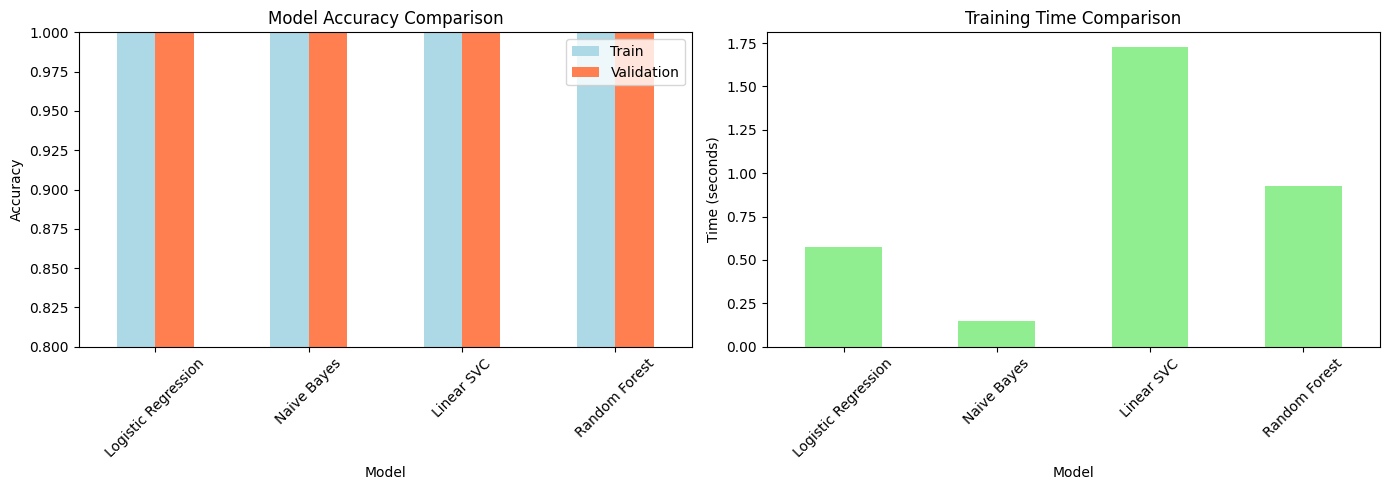


🏆 Best Model: Logistic Regression (Val Accuracy: 100.00%)


In [17]:
# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results_df.set_index('Model')[['Train Accuracy', 'Val Accuracy']].plot(
    kind='bar', ax=axes[0], color=['lightblue', 'coral']
)
axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([0.8, 1.0])
axes[0].legend(['Train', 'Validation'])
axes[0].tick_params(axis='x', rotation=45)

# Training time comparison
results_df.set_index('Model')['Train Time (s)'].plot(
    kind='bar', ax=axes[1], color='lightgreen'
)
axes[1].set_title('Training Time Comparison')
axes[1].set_ylabel('Time (seconds)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Select best model
best_model_name = results_df.loc[results_df['Val Accuracy'].idxmax(), 'Model']
best_model_acc = results_df['Val Accuracy'].max()
print(f"\n🏆 Best Model: {best_model_name} (Val Accuracy: {best_model_acc*100:.2f}%)")

## 9. Hyperparameter Tuning (Best Model)

In [18]:
# Tune best model (usually Logistic Regression)
print("🔧 Hyperparameter Tuning for Logistic Regression...")
print("="*60)

param_grid = {
    'C': [0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'saga']
}

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
grid_search.fit(X_train_tfidf, y_train)
tuning_time = time.time() - start_time

print(f"\n✅ Tuning complete! Time: {tuning_time:.2f} seconds")
print(f"\n🏆 Best Parameters: {grid_search.best_params_}")
print(f"🏆 Best CV Score: {grid_search.best_score_*100:.2f}%")

# Best model
final_model = grid_search.best_estimator_

🔧 Hyperparameter Tuning for Logistic Regression...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

✅ Tuning complete! Time: 42.27 seconds

🏆 Best Parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
🏆 Best CV Score: 100.00%


## 10. Final Evaluation on Test Set

In [19]:
# Evaluate on test set
print("🎯 Final Evaluation on Test Set...")
print("="*60)

y_test_pred = final_model.predict(X_test_tfidf)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='weighted')
test_precision = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
test_recall = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)

print(f"\n📊 Test Set Performance:")
print(f"  Accuracy:  {test_accuracy*100:.2f}%")
print(f"  Precision: {test_precision*100:.2f}%")
print(f"  Recall:    {test_recall*100:.2f}%")
print(f"  F1-Score:  {test_f1*100:.2f}%")

print(f"\n📋 Detailed Classification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

🎯 Final Evaluation on Test Set...

📊 Test Set Performance:
  Accuracy:  100.00%
  Precision: 100.00%
  Recall:    100.00%
  F1-Score:  100.00%

📋 Detailed Classification Report:
                            precision    recall  f1-score   support

       Charity & Donations       1.00      1.00      1.00       150
Entertainment & Recreation       1.00      1.00      1.00       150
        Financial Services       1.00      1.00      1.00       150
             Food & Dining       1.00      1.00      1.00       150
        Government & Legal       1.00      1.00      1.00       150
      Healthcare & Medical       1.00      1.00      1.00       150
                    Income       1.00      1.00      1.00       150
         Shopping & Retail       1.00      1.00      1.00       150
            Transportation       1.00      1.00      1.00       150
      Utilities & Services       1.00      1.00      1.00       150

                  accuracy                           1.00      1500
    

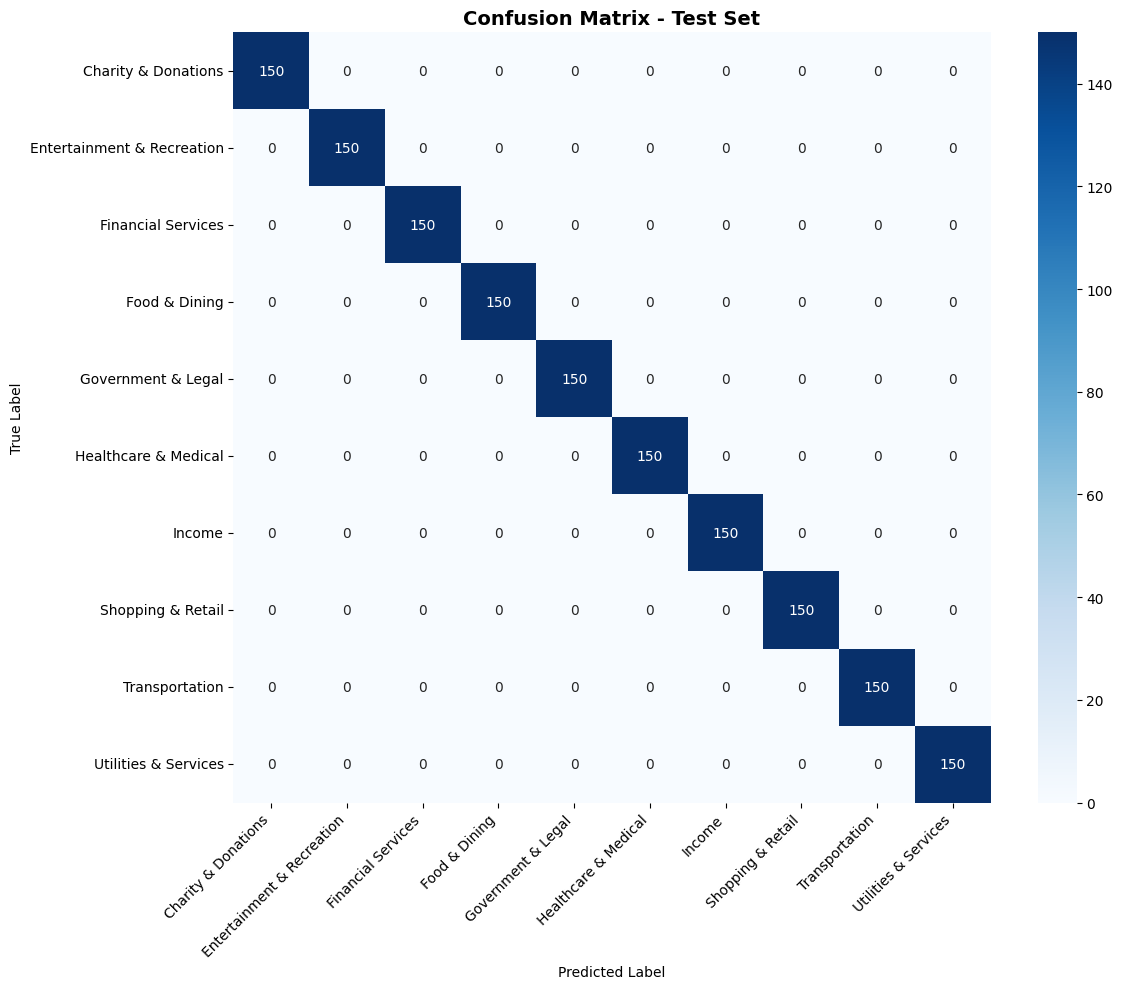

In [20]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=sorted(df['category'].unique()),
            yticklabels=sorted(df['category'].unique()))
plt.title('Confusion Matrix - Test Set', fontsize=14, fontweight='bold')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Save Final Model

In [21]:
# Save model and vectorizer
import os
os.makedirs('../models', exist_ok=True)

model_path = '../models/arabic_balanced_classifier.joblib'
vectorizer_path = '../models/arabic_balanced_vectorizer.joblib'

joblib.dump(final_model, model_path)
joblib.dump(tfidf, vectorizer_path)

print("💾 Model saved successfully!")
print(f"  Model: {model_path}")
print(f"  Vectorizer: {vectorizer_path}")

# Save model metadata
metadata = {
    'model_name': 'Arabic Balanced Classifier with Diacritics',
    'dataset': 'arabic_balanced_diacritics_clean.csv',
    'total_samples': len(df),
    'train_samples': len(X_train),
    'val_samples': len(X_val),
    'test_samples': len(X_test),
    'test_accuracy': float(test_accuracy),
    'test_f1': float(test_f1),
    'num_categories': len(df['category'].unique()),
    'categories': sorted(df['category'].unique()),
    'best_params': grid_search.best_params_,
    'training_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('../models/arabic_balanced_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("\n✅ Model metadata saved!")
print("\n" + "="*60)
print("🎉 PIPELINE COMPLETE!")
print("="*60)

💾 Model saved successfully!
  Model: ../models/arabic_balanced_classifier.joblib
  Vectorizer: ../models/arabic_balanced_vectorizer.joblib

✅ Model metadata saved!

🎉 PIPELINE COMPLETE!
